# EfficientNet-B0: Two-Stage Fine-Tuning Pipeline

This notebook executes **STEP 1B**: Two-Stage Fine-Tuning for EfficientNet-B0 on Diabetic Retinopathy (APTOS 2019).

### Pipeline Architecture:
* **Stage 1: Head Warmup (5 Epochs)**
  - Pretrained ImageNet backbone frozen (`requires_grad = False`)
  - BatchNorm running stats frozen (`eval()` mode for BN layers)
  - Trainable head: Dropout(0.4) -> Linear(1280 -> 5)
  - Optimizer: AdamW (`lr = 1e-3`, `weight_decay = 1e-4`)
  - Loss: Standard unweighted CrossEntropyLoss
  - Model selection on validation loss; best checkpoint saved to `efficientnet_b0_stage1_best.pth`

* **Stage 2: Full Fine-Tuning (Up to 30 Epochs)**
  - Loads best checkpoint from Stage 1
  - Backbone unfrozen (`requires_grad = True`)
  - Differential parameter groups: Backbone (`lr = 1e-5`), Classifier Head (`lr = 1e-4`)
  - Cosine annealing scheduler with 3 warmup epochs
  - Early stopping patience = 7 epochs
  - Best checkpoint saved to `efficientnet_b0_stage2_best.pth`

* **Validation Evaluation & Diagnostics:**
  - Strictly evaluated on `val.csv` (549 samples; held-out `test.csv` is NOT used for tuning/selection)
  - Metrics: Accuracy, Macro F1, QWK, Per-Class Sensitivity, Confusion Matrix
  - Plots: Loss curves, Accuracy curves, Combined transition, Confusion matrix

## 1. Environment & GPU Setup

In [ ]:
import os
import sys

# ---- Mount Google Drive (if in Colab) ----
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive mounted successfully.")
except ImportError:
    print("Running outside Google Colab.")

# ---- Configure PROJECT_ROOT ----
PROJECT_ROOT = "/content/drive/MyDrive/DR_project"
if not os.path.isdir(PROJECT_ROOT):
    for cand in ["/content/drive/MyDrive/DR_Project", "/content/drive/Shareddrives/DR_project", "."]:
        if os.path.isdir(cand):
            PROJECT_ROOT = os.path.abspath(cand)
            break

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import torch
import torchvision

print("=" * 65)
print("              HARDWARE & ENVIRONMENT CONFIGURATION             ")
print("=" * 65)
print(f"  Project Root:        {PROJECT_ROOT}")
print(f"  Python Version:      {sys.version.split()[0]}")
print(f"  PyTorch Version:     {torch.__version__}")
print(f"  CUDA Available:      {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"  GPU Device:          {torch.cuda.get_device_name(0)}")
    device = torch.device('cuda')
else:
    print("  GPU Device:          None (CPU fallback)")
    device = torch.device('cpu')
print("=" * 65)

Mounted at /content/drive
Google Drive mounted successfully.
              HARDWARE & ENVIRONMENT CONFIGURATION             
  Project Root:        /content/drive/MyDrive/DR_project
  Python Version:      3.13.15
  PyTorch Version:     2.11.0+cu130
  CUDA Available:      True
  GPU Device:          Tesla T4


## 2. Imports, Output Directories, and Reproducibility Seed

In [ ]:
import gc
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.training.trainer import set_seed
from src.data.dataloader import get_dataloaders
from src.models.efficientnet import build_efficientnet_b0
from src.training.two_stage_pipeline import run_efficientnet_two_stage_pipeline
from src.evaluation.evaluator import evaluate_model
from src.evaluation.metrics import DR_CLASS_NAMES

SEED = 42
set_seed(SEED)

CKPT_DIR = os.path.join(PROJECT_ROOT, "checkpoints")
METRICS_DIR = os.path.join(PROJECT_ROOT, "results", "metrics")
PLOTS_DIR = os.path.join(PROJECT_ROOT, "results", "plots")

for d in [CKPT_DIR, METRICS_DIR, PLOTS_DIR]:
    os.makedirs(d, exist_ok=True)

print(f"Output directories verified.")
print(f"Global random seed set to: {SEED}")

Output directories verified.
Global random seed set to: 42


## 3. DataLoaders Setup (Train & Validation Only)

Strictly loads `train.csv` (2,563 images) and `val.csv` (549 images). The test set `test.csv` is NOT loaded here to ensure no data leakage or test-set-driven model selection.

In [ ]:
SPLITS_DIR = os.path.join(PROJECT_ROOT, "src", "data", "splits")
RAW_IMG_DIR = os.path.join(PROJECT_ROOT, "src", "data", "raw", "train_images")

BATCH_SIZE = 32
NUM_WORKERS = 2 if os.name != 'nt' else 0

dataloaders = get_dataloaders(
    splits_dir=SPLITS_DIR,
    img_dir=RAW_IMG_DIR,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    img_size=224,
    pin_memory=torch.cuda.is_available(),
)

train_loader = dataloaders["train"]
val_loader = dataloaders["val"]

print("=" * 65)
print("                   DATASET SIZES & BATCHES                     ")
print("=" * 65)
print(f"  Train Samples:      {len(train_loader.dataset):>5} ({len(train_loader)} batches)")
print(f"  Validation Samples: {len(val_loader.dataset):>5} ({len(val_loader)} batches)")
print(f"  Batch Size:         {BATCH_SIZE:>5}")
print("=" * 65)

                   DATASET SIZES & BATCHES                     
  Train Samples:       2563 (81 batches)
  Validation Samples:   549 (18 batches)
  Batch Size:            32


## 4. Execute Two-Stage Fine-Tuning Pipeline

- **Stage 1**: 5 epochs warmup (Head lr = 1e-3, Backbone frozen, BN running stats frozen)
- **Stage 2**: 30 epochs full fine-tuning (Backbone lr = 1e-5, Head lr = 1e-4, Warmup 3 epochs + Cosine decay, Patience = 7)
- Existing baseline checkpoint (`efficientnet_b0_best.pth`) is preserved untouched.

In [4]:
start_time = time.time()

results = run_efficientnet_two_stage_pipeline(
    train_loader=train_loader,
    val_loader=val_loader,
    checkpoint_dir=CKPT_DIR,
    stage1_filename="efficientnet_b0_stage1_best.pth",
    stage2_filename="efficientnet_b0_stage2_best.pth",
    stage1_epochs=5,
    stage2_epochs=30,
    stage2_warmup_epochs=3,
    stage1_lr=1e-3,
    stage2_backbone_lr=1e-5,
    stage2_head_lr=1e-4,
    weight_decay=1e-4,
    early_stopping_patience=7,
    device=device,
    seed=SEED,
)

total_duration = time.time() - start_time
print(f"\nTraining completed in {total_duration:.1f}s ({total_duration/60:.2f} min).")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 149MB/s]



      STAGE 1: CLASSIFICATION HEAD WARMUP (FROZEN BACKBONE)      
  Total Parameters:      4,013,953
  Trainable Parameters:  6,405 (Head only)
  Frozen Parameters:     4,007,548 (Backbone)
            TRAINING STARTED [STAGE1_WARMUP]            
  Device:              cuda
  Mixed Precision:     True
  Max Epochs:          5
  Early Stop Patience: 0
  Checkpoint File:     efficientnet_b0_stage1_best.pth
  Freeze BatchNorm:    True
  LR (Group 0):          1.00e-03
  [stage1_warmup] Epoch [ 1/ 5]  Train Loss: 0.9265  Train Acc: 0.6656  |  Val Loss: 0.7711  Val Acc: 0.7213  |  LR: 0.001000  (1551.1s)
         -> New best stage1_warmup model saved! (val_loss improved by inf) -> /content/drive/MyDrive/DR_project/checkpoints/efficientnet_b0_stage1_best.pth
  [stage1_warmup] Epoch [ 2/ 5]  Train Loss: 0.7081  Train Acc: 0.7405  |  Val Loss: 0.6965  Val Acc: 0.7577  |  LR: 0.001000  (390.0s)
         -> New best stage1_warmup model saved! (val_loss improved by 0.0746) -> /content/drive/MyDr

## 5. Save Histories and Generate Plots

Saved Stage 1 history: /content/drive/MyDrive/DR_project/results/metrics/efficientnet_b0_stage1_training_history.csv
Saved Stage 2 history: /content/drive/MyDrive/DR_project/results/metrics/efficientnet_b0_stage2_training_history.csv


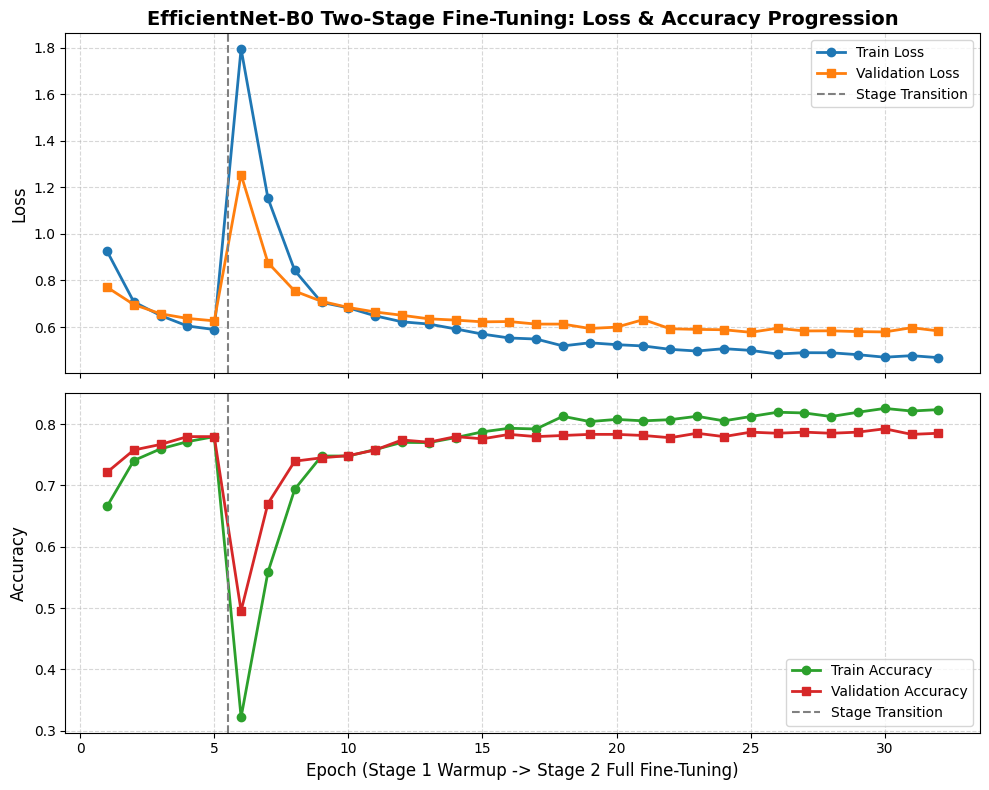

In [5]:
# 1. Save Histories to CSV
h1_path = os.path.join(METRICS_DIR, "efficientnet_b0_stage1_training_history.csv")
h2_path = os.path.join(METRICS_DIR, "efficientnet_b0_stage2_training_history.csv")

df_h1 = pd.DataFrame(results["history_stage1"])
df_h1.insert(0, "epoch", range(1, len(df_h1) + 1))
df_h1.to_csv(h1_path, index=False)

df_h2 = pd.DataFrame(results["history_stage2"])
df_h2.insert(0, "epoch", range(1, len(df_h2) + 1))
df_h2.to_csv(h2_path, index=False)
print(f"Saved Stage 1 history: {h1_path}")
print(f"Saved Stage 2 history: {h2_path}")

# 2. Combined Plotting Function
h1 = results["history_stage1"]
h2 = results["history_stage2"]
s1_len = len(h1["train_loss"])
s2_len = len(h2["train_loss"])
x = list(range(1, s1_len + s2_len + 1))

train_loss = list(h1["train_loss"]) + list(h2["train_loss"])
val_loss = list(h1["val_loss"]) + list(h2["val_loss"])
train_acc = list(h1["train_accuracy"]) + list(h2["train_accuracy"])
val_acc = list(h1["val_accuracy"]) + list(h2["val_accuracy"])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax1.plot(x, train_loss, 'o-', color='#1f77b4', label='Train Loss', linewidth=2)
ax1.plot(x, val_loss, 's-', color='#ff7f0e', label='Validation Loss', linewidth=2)
ax1.axvline(x=s1_len + 0.5, color='gray', linestyle='--', linewidth=1.5, label='Stage Transition')
ax1.set_ylabel('Loss', fontsize=12)
ax1.set_title('EfficientNet-B0 Two-Stage Fine-Tuning: Loss & Accuracy Progression', fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper right', fontsize=10)

ax2.plot(x, train_acc, 'o-', color='#2ca02c', label='Train Accuracy', linewidth=2)
ax2.plot(x, val_acc, 's-', color='#d62728', label='Validation Accuracy', linewidth=2)
ax2.axvline(x=s1_len + 0.5, color='gray', linestyle='--', linewidth=1.5, label='Stage Transition')
ax2.set_xlabel('Epoch (Stage 1 Warmup -> Stage 2 Full Fine-Tuning)', fontsize=12)
ax2.set_ylabel('Accuracy', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='lower right', fontsize=10)

plt.tight_layout()
combined_plot_path = os.path.join(PLOTS_DIR, "efficientnet_b0_two_stage_loss_acc.png")
plt.savefig(combined_plot_path, dpi=300)
plt.show()

## 6. Validation Evaluation on Best Stage 2 Model

Evaluates the best Stage 2 checkpoint strictly on `val.csv` (549 samples) to compute Accuracy, Macro F1, QWK, per-class sensitivity, and confusion matrix.

                  EVALUATION REPORT                    
  Samples Evaluated:            549
  Total Parameters:       4,013,953
  Trainable Parameters:       6,405
  Inference Time:             64.00s
  Throughput:                   8.6 samples/s

              CLASSIFICATION METRICS REPORT             
  Accuracy:                    0.7869
  Precision (macro):           0.6737
  Precision (weighted):        0.7760
  Recall (macro):              0.5473
  Recall (weighted):           0.7869
  F1 Score (macro):            0.5679
  F1 Score (weighted):         0.7621
  Sensitivity (macro):         0.5473
  Specificity (macro):         0.9403
  Quadratic Weighted Kappa:    0.8176
  ROC-AUC (macro):             N/A (no probabilities)
  ROC-AUC (weighted):          N/A (no probabilities)
------------------------------------------------------------
  Per-Class Sensitivity & Specificity:
    0 - No DR                  Sens=0.9705   Spec=0.9353
    1 - Mild                   Sens=0.4182   Spec=

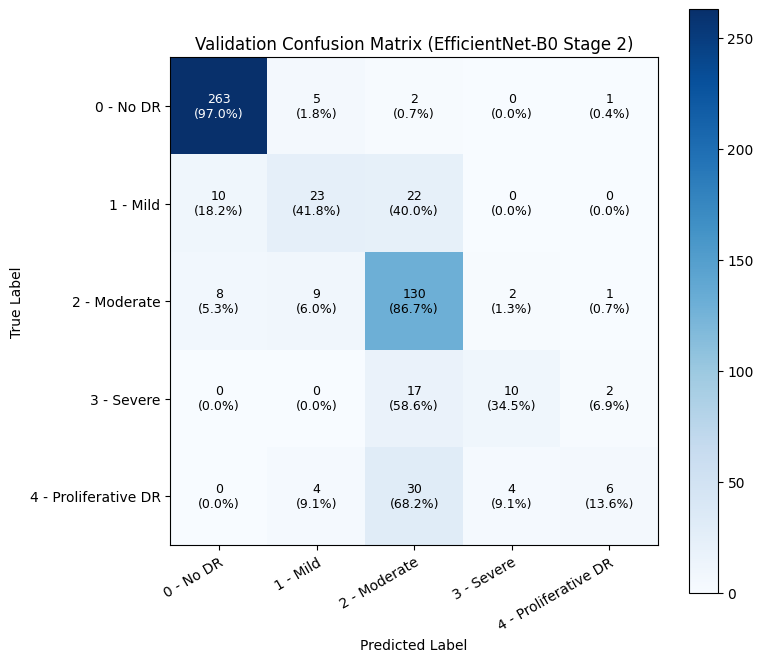

In [6]:
best_stage2_model = build_efficientnet_b0(num_classes=5, pretrained=False)
ckpt = torch.load(results["stage2_checkpoint_path"], map_location=device, weights_only=False)
best_stage2_model.load_state_dict(ckpt["model_state_dict"])

val_eval = evaluate_model(
    model=best_stage2_model,
    dataloader=val_loader,
    device=device,
    num_classes=5,
    verbose=True,
)

val_metrics = val_eval["metrics"]

# Save metrics JSON
val_json_path = os.path.join(METRICS_DIR, "efficientnet_b0_stage2_val_metrics.json")
with open(val_json_path, "w") as f:
    json.dump(val_metrics, f, indent=4)
print(f"\nSaved validation metrics JSON: {val_json_path}")

# Plot Confusion Matrix Heatmap
cm = np.array(val_metrics["confusion_matrix"])
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
ax.figure.colorbar(im, ax=ax)
ax.set(
    xticks=np.arange(len(DR_CLASS_NAMES)),
    yticks=np.arange(len(DR_CLASS_NAMES)),
    xticklabels=DR_CLASS_NAMES,
    yticklabels=DR_CLASS_NAMES,
    title='Validation Confusion Matrix (EfficientNet-B0 Stage 2)',
    ylabel='True Label',
    xlabel='Predicted Label'
)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")
thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        pct = (cm[i, j] / cm[i].sum() * 100) if cm[i].sum() > 0 else 0
        ax.text(j, i, f"{cm[i, j]}\n({pct:.1f}%)", ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black", fontsize=9)
plt.tight_layout()
cm_path = os.path.join(PLOTS_DIR, "efficientnet_b0_stage2_confusion_matrix.png")
plt.savefig(cm_path, dpi=300)
plt.show()

## 7. Diagnostics & Analysis Report

In [7]:
h2 = results["history_stage2"]
best_val_loss = min(h2["val_loss"])
best_epoch_s2 = h2["val_loss"].index(best_val_loss) + 1
total_s2 = len(h2["val_loss"])

stopping_reason = (
    f"Early stopping triggered (patience=7) at Stage 2 epoch {total_s2}"
    if total_s2 < 30
    else "Completed full 30 epochs"
)

final_train_loss = h2["train_loss"][-1]
final_val_loss = h2["val_loss"][-1]
gap = final_val_loss - final_train_loss
overfitting = "HIGH (val_loss >> train_loss)" if gap > 0.4 else "MODERATE/LOW"

min_sens_cls = int(np.argmin(val_metrics["sensitivity_per_class"]))
min_sens = val_metrics["sensitivity_per_class"][min_sens_cls]

print("=" * 70)
print("               TWO-STAGE PIPELINE RUN SUMMARY & DIAGNOSTICS             ")
print("=" * 70)
print(f"  Stage 1 Best Checkpoint: {results['stage1_checkpoint_path']}")
print(f"  Stage 2 Best Checkpoint: {results['stage2_checkpoint_path']}")
print(f"  Stage 2 Best Epoch:      {best_epoch_s2} (Val Loss: {best_val_loss:.4f})")
print(f"  Stage 2 Stopping Reason: {stopping_reason}")
print(f"  Total Duration:          {total_duration:.1f}s ({total_duration/60:.2f} min)")
print(f"  Validation Accuracy:     {val_metrics['accuracy']:.4f}")
print(f"  Validation Macro F1:     {val_metrics['f1_macro']:.4f}")
print(f"  Validation QWK:          {val_metrics['quadratic_weighted_kappa']:.4f}")
print(f"  Overfitting Check:       {overfitting} (Train Loss: {final_train_loss:.4f}, Val Loss: {final_val_loss:.4f})")
print(f"  Minority Class Check:    Class {min_sens_cls} ({DR_CLASS_NAMES[min_sens_cls]}) sensitivity is {min_sens:.4f}")
print("=" * 70)

               TWO-STAGE PIPELINE RUN SUMMARY & DIAGNOSTICS             
  Stage 1 Best Checkpoint: /content/drive/MyDrive/DR_project/checkpoints/efficientnet_b0_stage1_best.pth
  Stage 2 Best Checkpoint: /content/drive/MyDrive/DR_project/checkpoints/efficientnet_b0_stage2_best.pth
  Stage 2 Best Epoch:      20 (Val Loss: 0.5774)
  Stage 2 Stopping Reason: Early stopping triggered (patience=7) at Stage 2 epoch 27
  Total Duration:          13458.9s (224.32 min)
  Validation Accuracy:     0.7869
  Validation Macro F1:     0.5679
  Validation QWK:          0.8176
  Overfitting Check:       MODERATE/LOW (Train Loss: 0.4685, Val Loss: 0.5834)
  Minority Class Check:    Class 4 (4 - Proliferative DR) sensitivity is 0.1364
